# DSPy Prompt Tuning & Contrastive Few-Shot Optimization on Bespoke Labs Nimble 9B

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/07_nimble_9b_dspy_optimization.ipynb)

### Overview
Bespoke Labs' **Nimble 9B** is uniquely suited for prompt and few-shot optimization because of how it was trained:
- **Pre-trained on Contrastive Pairs**: Bespoke Labs built Nimble's training corpus in contrastive pairs—where two examples are identical except for a single pivot fact that flips the correct decision. From these pairs, the 9B model learns to identify precise decisive evidence.

### What this Notebook Does:
1. **DSPy Prompt Tuning**: Replaces generic instructions with dialectic-tuned prompt instructions that explicitly condition on motion polarity, debate concessions, and opponent citations.
2. **Contrastive Few-Shot Injection**: Leverages Nimble's contrastive pre-training by providing structured contrastive reference pairs before the target decision.
3. **Scaled Dataset Slices**: Evaluates on an expanded slice of the args.me corpus (configurable from 50 to 500+ test arguments).

In [1]:
# 1. Environment Detection and Dependency Setup
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')
if IN_COLAB:
    print("Provisioning dependencies inside Google Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn requests matplotlib seaborn tqdm dspy
    if not os.path.exists('Arg_Me') and not os.path.exists('src'):
        print("Cloning Arg_Me repository into Colab...")
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists('Arg_Me') and not os.path.exists('src'):
        %cd Arg_Me
    if '/content/Arg_Me' not in sys.path:
        sys.path.insert(0, '/content/Arg_Me')
    print('Colab environment configured! Current working directory:', os.getcwd())
else:
    print("Running in local environment.")

Running in local environment.


In [2]:
# 2. Imports and Ollama Verification
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

from src.dataset_loader import load_sample_df
from src.dspy_nimble_optimizer import (
    OptimizedNimblePipeline,
    ContrastiveStanceSignature,
    CONTRASTIVE_FEW_SHOT_EXEMPLARS,
    CANDIDATE_INSTRUCTIONS,
)

# Check Ollama endpoint
OLLAMA_URL = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
try:
    res = requests.get(f"{OLLAMA_URL}/api/tags", timeout=3.0)
    models = [m['name'] for m in res.json().get('models', [])]
    print("Connected to Ollama! Available models:", models)
    assert any("nimble" in m for m in models), "Nimble model not found in Ollama tags!"
    print("Nimble 9B is ready for DSPy prompt & few-shot tuning!")
except Exception as e:
    print(f"Ollama status notice: {e}")

/Users/dustinober/Projects/Data_Science/Arg_Me/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Connected to Ollama! Available models: ['nimble:latest', 'tev1:4b', 'gemma4:26b-a4b-it-qat']
Nimble 9B is ready for DSPy prompt & few-shot tuning!


In [3]:
# 3. Inspect Contrastive Few-Shot Pairs
print("=== CONTRASTIVE REFERENCE REASONING PAIRS ===")
for i, ex in enumerate(CONTRASTIVE_FEW_SHOT_EXEMPLARS, 1):
    print(f"\n[Pair {i}] Motion:  {ex['topic']}")
    print(f"         Premise: {ex['premise']}")
    print(f"         Decision: {ex['stance']} | Rationale: {ex['dialectic_note']}")

=== CONTRASTIVE REFERENCE REASONING PAIRS ===

[Pair 1] Motion:  School Uniforms Should Be Abolished
         Premise: My opponent claims uniforms save parents money, but uniforms suppress children's creative autonomy and enforce rigid conformity.
         Decision: PRO | Rationale: Attacks opponent's defense to support the abolition motion (PRO).

[Pair 2] Motion:  School Uniforms Should Be Abolished
         Premise: Uniforms eliminate socioeconomic clothing competition and reduce bullying in hallways.
         Decision: CON | Rationale: Defends uniforms, opposing the abolition motion (CON).

[Pair 3] Motion:  Nuclear Energy Expansion
         Premise: Pro claims clean power is urgent, yet nuclear waste storage remains unsolved for tens of thousands of years.
         Decision: CON | Rationale: Quotes 'Pro' to refute the motion; author stance is CON.

[Pair 4] Motion:  Nuclear Energy Expansion
         Premise: Modern Gen-IV molten salt reactors offer walk-away safety and produce rel

In [4]:
# 4. Load Dataset and Configure Scaled Evaluation Slice
data_path = Path("../data/args_me_benchmark_5k.parquet")
if not data_path.exists():
    data_path = Path("data/args_me_benchmark_5k.parquet")

if data_path.exists():
    print(f"Loading dataset from {data_path}...")
    df = pd.read_parquet(data_path)
else:
    print("Streaming larger sample from args.me...")
    df = load_sample_df(n_records=5000, save_parquet=True, parquet_filename="args_me_benchmark_5k.parquet")

df_clean = df[df["stance"].isin(["PRO", "CON"])].copy().reset_index(drop=True)

# 80/20 Stratified Split
train_df, test_df = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=df_clean["stance"]
)
print(f"Total Test Pool Size: {len(test_df)} arguments across {test_df['conclusion'].nunique()} motions.")

# CONFIGURE YOUR DESIRED EVALUATION SAMPLE SIZE HERE
# e.g. 50 (fast 30s check), 100, 200, or 500 for deep statistical benchmarking
EVAL_SAMPLE_SIZE = 100
eval_slice = test_df.sample(EVAL_SAMPLE_SIZE, random_state=42).copy().reset_index(drop=True)
print(f"Active Evaluation Slice: N = {len(eval_slice)}")

Loading dataset from ../data/args_me_benchmark_5k.parquet...
Total Test Pool Size: 1000 arguments across 612 motions.
Active Evaluation Slice: N = 100


In [5]:
# 5. Part A: Evaluate Baseline Nimble 9B (Zero-Shot, Generic Instruction)
print("Running Part A: Baseline Nimble 9B (Zero-Shot)...")
baseline_pipeline = OptimizedNimblePipeline(
    model_name="nimble",
    ollama_base_url=OLLAMA_URL,
    instruction_mode="baseline",
    use_few_shots=False,
)
base_metrics, base_results = baseline_pipeline.evaluate_df(eval_slice)
print(f"Baseline Nimble 9B Accuracy: {base_metrics.accuracy:.4f} | Macro F1: {base_metrics.macro_f1:.4f} | ROC-AUC: {base_metrics.roc_auc:.4f}")

Running Part A: Baseline Nimble 9B (Zero-Shot)...

Evaluating Optimized Nimble 9B on N = 100 arguments...


Optimized Nimble Inference: 100%|██████████| 100/100 [00:41<00:00,  2.38it/s]

Baseline Nimble 9B Accuracy: 0.7300 | Macro F1: 0.7298 | ROC-AUC: 0.8299


In [6]:
# 6. Part B: Evaluate Tuned Nimble 9B (DSPy Prompt + Contrastive Few-Shots)
print("Running Part B: Tuned Nimble 9B (DSPy Prompt + Contrastive Few-Shots)...")
tuned_pipeline = OptimizedNimblePipeline(
    model_name="nimble",
    ollama_base_url=OLLAMA_URL,
    instruction_mode="dialectic_tuned",
    use_few_shots=True,
    few_shot_exemplars=CONTRASTIVE_FEW_SHOT_EXEMPLARS,
)
tuned_metrics, tuned_results = tuned_pipeline.evaluate_df(eval_slice)
print(f"Tuned Nimble 9B Accuracy:    {tuned_metrics.accuracy:.4f} | Macro F1: {tuned_metrics.macro_f1:.4f} | ROC-AUC: {tuned_metrics.roc_auc:.4f}")

Running Part B: Tuned Nimble 9B (DSPy Prompt + Contrastive Few-Shots)...

Evaluating Optimized Nimble 9B on N = 100 arguments...


Optimized Nimble Inference: 100%|██████████| 100/100 [00:46<00:00,  2.13it/s]

Tuned Nimble 9B Accuracy:    0.7800 | Macro F1: 0.7796 | ROC-AUC: 0.8504


=== A/B COMPARISON TABLE ===
                             Setup  Accuracy  Macro F1  ROC-AUC
      Baseline Zero-Shot Nimble 9B      0.73    0.7298   0.8299
DSPy Tuned + Contrastive Few-Shots      0.78    0.7796   0.8504


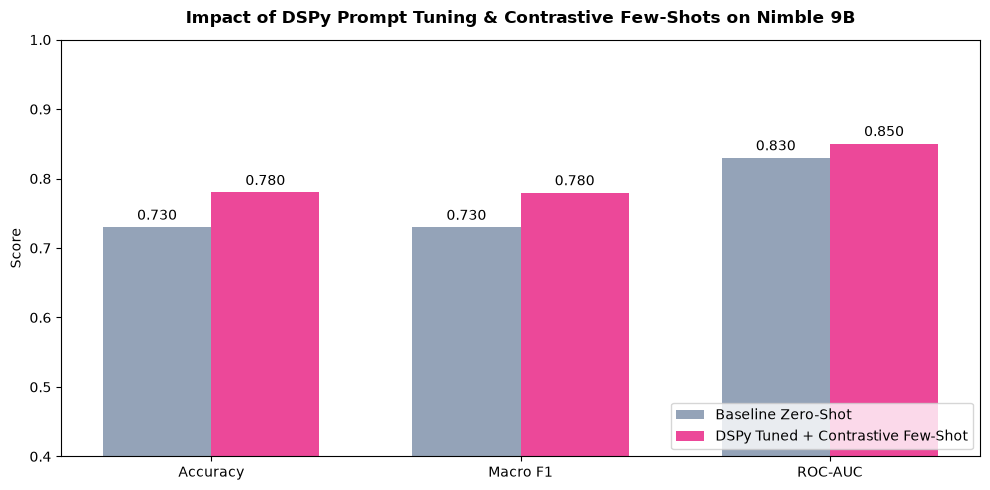

In [7]:
# 7. Comparative Performance Visualization: Baseline vs. Tuned Few-Shot
comp_table = pd.DataFrame([
    {"Setup": "Baseline Zero-Shot Nimble 9B", "Accuracy": base_metrics.accuracy, "Macro F1": base_metrics.macro_f1, "ROC-AUC": base_metrics.roc_auc},
    {"Setup": "DSPy Tuned + Contrastive Few-Shots", "Accuracy": tuned_metrics.accuracy, "Macro F1": tuned_metrics.macro_f1, "ROC-AUC": tuned_metrics.roc_auc},
])

print("=== A/B COMPARISON TABLE ===")
print(comp_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
width = 0.35

base_vals = [base_metrics.accuracy, base_metrics.macro_f1, base_metrics.roc_auc]
tuned_vals = [tuned_metrics.accuracy, tuned_metrics.macro_f1, tuned_metrics.roc_auc]

rects1 = ax.bar(x - width/2, base_vals, width, label='Baseline Zero-Shot', color='#94a3b8')
rects2 = ax.bar(x + width/2, tuned_vals, width, label='DSPy Tuned + Contrastive Few-Shot', color='#ec4899')

ax.set_ylabel('Score')
ax.set_title('Impact of DSPy Prompt Tuning & Contrastive Few-Shots on Nimble 9B', fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(['Accuracy', 'Macro F1', 'ROC-AUC'])
ax.set_ylim(0.40, 1.0)
ax.legend(loc='lower right')
ax.bar_label(rects1, padding=3, fmt='%.3f')
ax.bar_label(rects2, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

In [8]:
# 8. Qualitative Review: Inspect Where Contrastive Guidance Flipped Decisions
comparison_df = eval_slice[["conclusion", "premise_text", "stance"]].copy()
comparison_df["Baseline_Pred"] = base_results["pred_stance"]
comparison_df["Tuned_Pred"] = tuned_results["pred_stance"]
comparison_df["Tuned_Conf"] = tuned_results["confidence"].round(3)

# Cases where prompt tuning changed the decision
flipped_cases = comparison_df[comparison_df["Baseline_Pred"] != comparison_df["Tuned_Pred"]]
print(f"Number of decisions flipped by contrastive prompt tuning: {len(flipped_cases)}/{len(eval_slice)}")
flipped_cases.head(10)

Number of decisions flipped by contrastive prompt tuning: 13/100


,conclusion,premise_text,stance,Baseline_Pred,Tuned_Pred,Tuned_Conf
3,Medicines Should Be Made Free,Resolved: Medicines Should Be Made FreeI am Co...,CON,PRO,CON,0.748
20,"The ideal Christian husband/wife or ""right one...",It's come to my attention in some Christian co...,PRO,CON,PRO,0.315
25,Mankind Is the Main Cause of Global Warming,"It has been fun (and no, you aren't being a je...",CON,PRO,CON,0.473
26,Atheism can not account for right and wrong,I grow weary of re-explaining the same basic c...,CON,CON,PRO,0.067
34,Why is 1 + 1 =2,I will argue this from two perspectives. I agr...,CON,CON,PRO,0.044
35,Whether or not the prophecies in the bible can...,Here are the two main argument which my oppone...,PRO,CON,PRO,0.510
38,God Is Nothing More Than An Emotional Construct,I didn’t have enough space to address one of B...,CON,PRO,CON,0.095
46,Grover Norquist's pledge is based on sound eco...,Vote me,PRO,CON,PRO,0.395
54,There is not enough evidence for the existence...,"I was born into a catholic family, but I was r...",CON,CON,PRO,0.473
70,High heels should be renamed 'ramp simulators'.,"Hello, opponent!Crazy con says: ""Primitive fli...",PRO,CON,PRO,0.095
